MIloud meziane, Fedi burbita, mahmoud dahir al hussin

<div style="background:#0f172a; color:#e5e7eb; padding:14px 16px; border-radius:12px; border:1px solid #1f2937;">
  <h1 style="margin:0; color:#93c5fd;">Partie I — Apprentissage supervisé (Q1 → Q8)</h1>
  <p style="margin:8px 0 0 0;">
    Dataset : <code style="color:#e5e7eb;">credit_scoring.csv</code> — objectif : construire un modèle de crédit scoring et le déployer sous forme de pipeline (<code>pickle</code>).
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937;">
  <h2 style="margin:0; color:#93c5fd;">Objectif global</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Comparer plusieurs classifieurs supervisés sur une cible binaire <code>Status</code> (0/1).</li>
    <li>Tester l’impact de la normalisation puis de l’ajout de composantes ACP (PCA).</li>
    <li>Sélectionner un sous-ensemble de variables utile (performance + réduction de dimension).</li>
    <li>Optimiser le modèle retenu et sauvegarder une chaîne complète “prête production”.</li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #f59e0b;">
  <h2 style="margin:0; color:#fbbf24;">Q1 — Chargement, description rapide et split</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Lecture du fichier avec <code>pandas.read_csv</code> (séparateur <code>;</code> puis fallback <code>,</code>).</li>
    <li>Séparation : <code>X</code> = 13 variables (features) et <code>y</code> = <code>Status</code>.</li>
    <li>Affichage des propriétés utiles : <code>shape</code> et répartition des classes (déséquilibre éventuel).</li>
    <li>Découpage 50/50 : <code>train_test_split(test_size=0.5, random_state=1, stratify=y)</code> pour garder la même proportion de classes dans train/test.</li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22c55e;">
  <h2 style="margin:0; color:#86efac;">Q2 — Comparaison des modèles + métriques</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Modèles comparés : CART, KNN (<code>k=5</code>), MLP (<code>(40,20)</code>).</li>
    <li>Métriques sur <b>le test</b> : matrice de confusion, Accuracy, Precision, Recall.</li>
    <li>ROC/AUC : score continu utilisé (<code>predict_proba</code> si dispo, sinon <code>decision_function</code>).</li>
  </ul>

  <h3 style="margin:12px 0 6px 0; color:#86efac;">Critère métier utilisé pour comparer</h3>
  <p style="margin:0;">
    En crédit scoring, un faux positif (accepter un mauvais dossier) peut coûter cher.
    On choisit donc de favoriser la <b>précision</b> via un score simple.
  </p>
</div>

<br>

$$\text{Score final}=\frac{\text{Accuracy}+\text{Precision}}{2}$$

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #60a5fa;">
  <h2 style="margin:0; color:#93c5fd;">Q3 — Normalisation</h2>
  <p style="margin:8px 0 0 0;">
    Application de <code>StandardScaler</code> : <b>fit sur train</b>, puis <b>transform sur test</b> (pas de fuite de données).
    On relance la comparaison CART/KNN/MLP sur les données normalisées.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #a78bfa;">
  <h2 style="margin:0; color:#c4b5fd;">Q4 — Ajout PCA(3) + concat (approche hybride)</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>PCA apprise sur le train normalisé, puis projection du test.</li>
    <li>3 composantes conservées : <code>PCA(n_components=3)</code>.</li>
    <li>Concaténation : <code>[X_standardized | PCA1 PCA2 PCA3]</code> → passage de 13 à 16 variables.</li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #e5e7eb;">
  <h2 style="margin:0; color:#e5e7eb;">Q5 — Sélection de variables + explicabilité</h2>
  <ol style="margin:8px 0 0 18px;">
    <li>Importance des variables par RandomForest (<code>n_estimators=1000</code>) sur le jeu “standardisé + PCA”.</li>
    <li>Choix de <code>best_k</code> : ajout progressif des variables triées par importance et observation de la performance (courbe).</li>
    <li>Lecture globale SHAP pour vérifier la cohérence des variables influentes.</li>
  </ol>
  <p style="margin:8px 0 0 0;">
    L’énoncé montre KNN en exemple, mais ici on utilise le modèle “meilleur” à l’étape précédente pour estimer <code>best_k</code>, ce qui correspond à l’idée “meilleur algorithme retenu”.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #fb7185;">
  <h2 style="margin:0; color:#fda4af;">Q6 — Optimisation par GridSearchCV</h2>
  <p style="margin:8px 0 0 0;">
    Optimisation du MLP via <code>GridSearchCV</code> (5-fold) en gardant uniquement les <code>best_k</code> variables.
    Score optimisé : le score métier.
  </p>
</div>

<br>

$$\text{Score métier}=\frac{\text{Accuracy}+\text{Precision}}{2}$$

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22d3ee;">
  <h2 style="margin:0; color:#67e8f9;">Q7 — Pipeline “production” + sauvegarde</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Pipeline : <code>StandardScaler → concat PCA(3) → sélection (RFE) → MLP optimisé</code>.</li>
    <li>Sauvegarde dans <code>credit_scoring.pkl</code> pour refaire exactement le même traitement en scoring.</li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #94a3b8;">
  <h2 style="margin:0; color:#cbd5e1;">Q8 — Orchestration</h2>
  <p style="margin:8px 0 0 0;">
    Une fonction orchestre Q1 → Q7 dans l’ordre, affiche les comparaisons, puis renvoie le pipeline final (et écrit le pickle sur disque).
  </p>
</div>



=========== STEP 0: Load & split ===========
Dataset shape: (4375, 14)
Classes: 3159 positifs (72.21%) / 1216 negatifs

=========== STEP 1: Raw data ===========

--- CART ---
Confusion matrix:
[[ 297  311]
 [ 319 1261]]
Accuracy: 0.712 | Precision: 0.802 | Recall: 0.798
AUC:      0.643
Final score = (Accuracy + Precision)/2 : 0.757

--- KNN ---
Confusion matrix:
[[ 180  428]
 [ 221 1359]]
Accuracy: 0.703 | Precision: 0.760 | Recall: 0.860
AUC:      0.648
Final score = (Accuracy + Precision)/2 : 0.732

--- MLP ---
Confusion matrix:
[[  59  549]
 [  55 1525]]
Accuracy: 0.724 | Precision: 0.735 | Recall: 0.965
AUC:      0.679
Final score = (Accuracy + Precision)/2 : 0.730


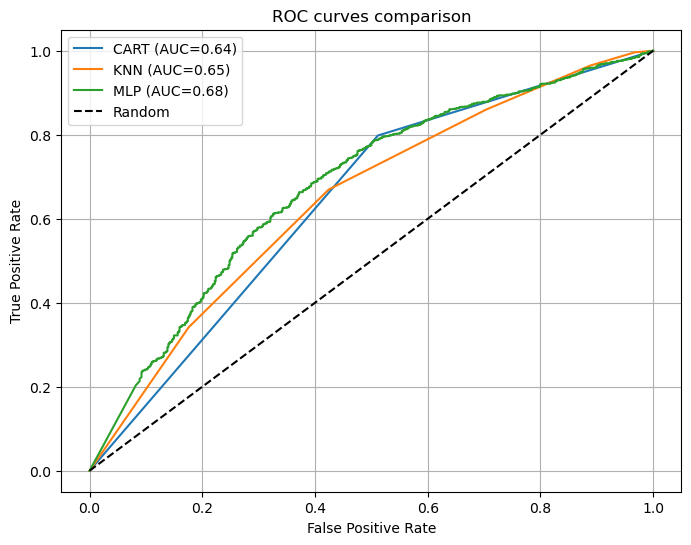


Best model: CART | best score: 0.757

=========== STEP 2: Standardized data ===========

COMPARISON AFTER STANDARDIZATION

--- CART ---
Confusion matrix:
[[ 302  306]
 [ 322 1258]]
Accuracy: 0.713 | Precision: 0.804 | Recall: 0.796
AUC:      0.646
Final score = (Accuracy + Precision)/2 : 0.759

--- KNN ---
Confusion matrix:
[[ 270  338]
 [ 212 1368]]
Accuracy: 0.749 | Precision: 0.802 | Recall: 0.866
AUC:      0.744
Final score = (Accuracy + Precision)/2 : 0.775

--- MLP ---
Confusion matrix:
[[ 353  255]
 [ 221 1359]]
Accuracy: 0.782 | Precision: 0.842 | Recall: 0.860
AUC:      0.817
Final score = (Accuracy + Precision)/2 : 0.812


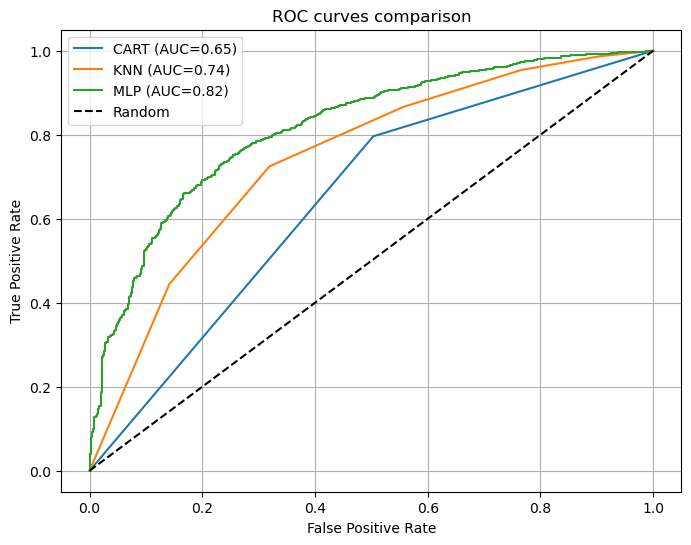


Best model: MLP | best score: 0.812

=========== STEP 3: Standardized + PCA concat ===========
PCA computation + concatenation
New train shape after concat: (2187, 16)

Comparison on standardized + PCA-concat features

--- CART ---
Confusion matrix:
[[ 305  303]
 [ 296 1284]]
Accuracy: 0.726 | Precision: 0.809 | Recall: 0.813
AUC:      0.657
Final score = (Accuracy + Precision)/2 : 0.768

--- KNN ---
Confusion matrix:
[[ 258  350]
 [ 206 1374]]
Accuracy: 0.746 | Precision: 0.797 | Recall: 0.870
AUC:      0.743
Final score = (Accuracy + Precision)/2 : 0.771

--- MLP ---
Confusion matrix:
[[ 353  255]
 [ 210 1370]]
Accuracy: 0.787 | Precision: 0.843 | Recall: 0.867
AUC:      0.821
Final score = (Accuracy + Precision)/2 : 0.815


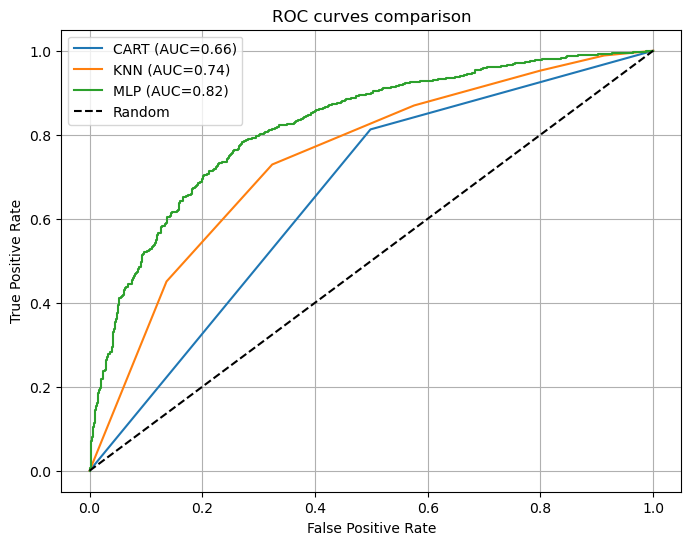


Best model: MLP | best score: 0.815

=========== STEP 4: Feature selection (importance + best_k + shap) ===========

[Q5.1] RandomForest feature importances
Features sorted by importance:
['Income' 'PCA2' 'Seniority' 'PCA3' 'Price' 'PCA1' 'Amount' 'Age' 'Assets'
 'Records' 'Expenses' 'Time' 'Job' 'Debt' 'Home' 'Marital']


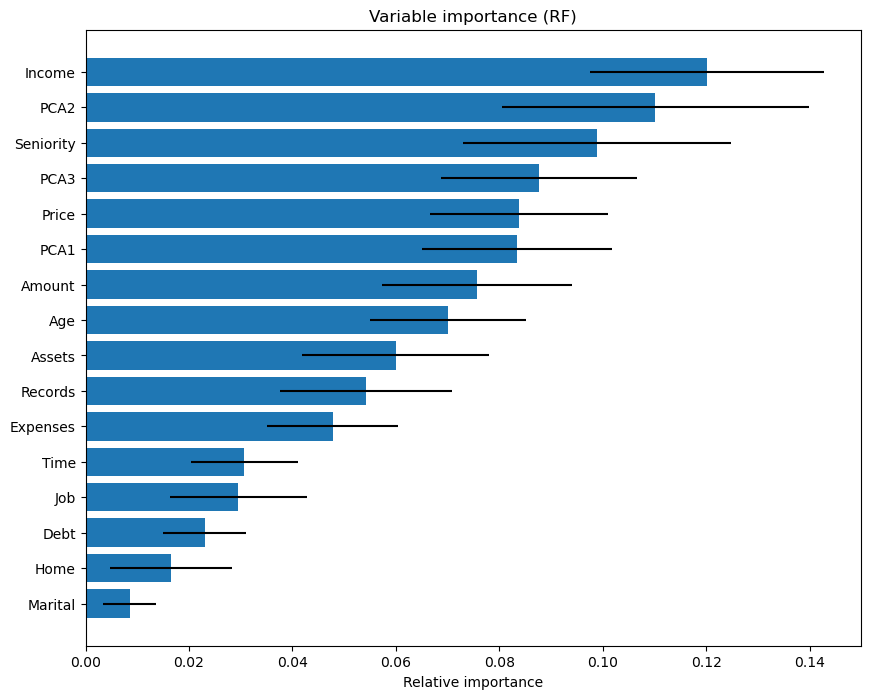


[Q5.2] Choosing the number of features (accuracy curve)


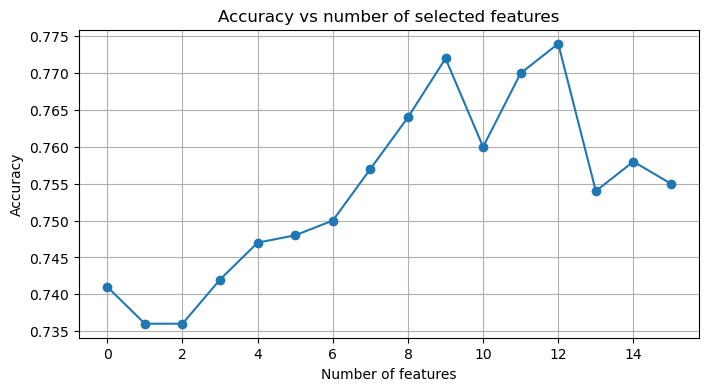

Best_k found: 13

[Q5.3] SHAP explainability (global)


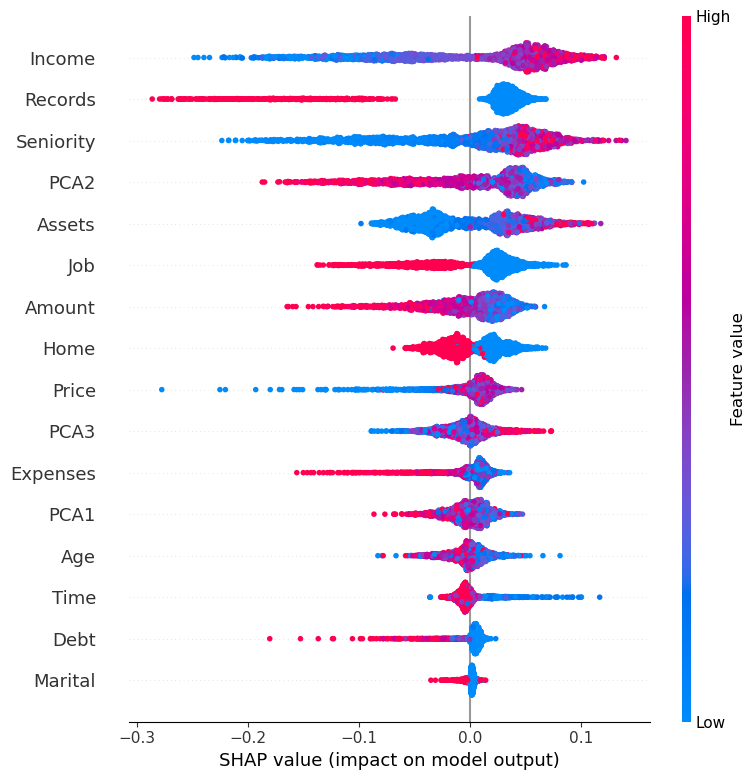


=========== STEP 5: Tuning ===========

[Q6] GridSearchCV on MLP (top 13 features)
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best params: {'alpha': 0.0001, 'hidden_layer_sizes': (40, 20), 'learning_rate_init': 0.001, 'solver': 'adam'}
Best CV score: 0.785

=========== STEP 6: Final pipeline + pickle ===========

[Q7] Building the final pipeline (train/test)
Pipeline saved to: credit_scoring.pkl

Orchestration finished.


,steps,"[('S', ...), ('FU', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,transformer_list,"[('ID', ...), ('PCA', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False


In [1]:
from utils import pipeline_generation_train_test_split

pipeline_tt = pipeline_generation_train_test_split("credit_scoring.csv", business_choice="precision")
pipeline_tt


<div style="background:#0f172a; color:#e5e7eb; padding:14px 16px; border-radius:12px; border:1px solid #1f2937;">
  <h1 style="margin:0; color:#93c5fd;">Analyse des résultats — Q1 → Q8</h1>
  <p style="margin:8px 0 0 0;">
    Commentaires sur les sorties obtenues (split 50/50 stratifié, métriques calculées sur le test).
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #f59e0b;">
  <h2 style="margin:0; color:#fbbf24;">Q1 — Jeu de données</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>4375 individus, 13 variables explicatives + 1 cible binaire.</li>
    <li>Déséquilibre : ~72% de <code>Status=1</code> vs ~28% de <code>Status=0</code>.</li>
    <li>Impact attendu : l’accuracy peut être “gonflée” si un modèle prédit trop souvent la classe majoritaire, d’où l’intérêt de ROC/AUC et de la précision.</li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22c55e;">
  <h2 style="margin:0; color:#86efac;">Q2 — Données brutes</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>AUC autour de 0.64–0.68 : séparation au-dessus du hasard mais encore limitée.</li>
    <li>Avec <code>(Accuracy + Precision)/2</code>, CART est le meilleur sur données brutes (score ≈ 0.757).</li>
    <li>Le MLP brut a un recall très élevé mais une précision plus faible : il a tendance à prédire souvent la classe majoritaire (1), ce qui est cohérent avec le déséquilibre.</li>
  </ul>
  <p style="margin:8px 0 0 0;">
    Les ROC restent proches de la diagonale : cohérent avec des AUC modestes.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #60a5fa;">
  <h2 style="margin:0; color:#93c5fd;">Q3 — Effet de la normalisation</h2>
  <p style="margin:8px 0 0 0;">
    Après <code>StandardScaler</code>, amélioration nette des modèles sensibles à l’échelle : KNN et surtout MLP.
    Le meilleur devient le MLP.
  </p>
  <ul style="margin:8px 0 0 18px;">
    <li>MLP : Accuracy ≈ 0.782, Precision ≈ 0.842, AUC ≈ 0.817, score final ≈ 0.812.</li>
  </ul>
  <p style="margin:8px 0 0 0;">
    Interprétation : la normalisation met toutes les variables sur une échelle comparable, ce qui stabilise les distances (KNN) et facilite l’optimisation (MLP).
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #a78bfa;">
  <h2 style="margin:0; color:#c4b5fd;">Q4 — Ajout PCA(3) + concat</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Passage de 13 à 16 variables (13 standardisées + 3 composantes PCA).</li>
    <li>MLP reste le meilleur, avec un léger gain : AUC ≈ 0.821 et score final ≈ 0.815.</li>
  </ul>
  <p style="margin:8px 0 0 0;">
    On retient donc l’approche <b>StandardScaler + PCA(3)</b> pour les étapes suivantes, car c’est celle qui obtient le meilleur score sur le test.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #e5e7eb;">
  <h2 style="margin:0; color:#e5e7eb;">Q5 — best_k + SHAP</h2>
  <p style="margin:8px 0 0 0;">
    L’importance RandomForest met en avant <code>Income</code>, puis des composantes PCA (<code>PCA2</code>, <code>PCA3</code>) et des variables liées au profil (<code>Seniority</code>, <code>Price</code>, <code>Amount</code>...).
  </p>
  <p style="margin:8px 0 0 0;">
    Pour <code>best_k</code>, la courbe de performance atteint son optimum à <b>13 variables</b>.
    Le TP montre KNN en exemple, mais ici on utilise le modèle retenu comme meilleur après Q3/Q4 (MLP), ce qui respecte l’idée “meilleur algorithme choisi précédemment”.
  </p>
  <p style="margin:8px 0 0 0;">
    SHAP est cohérent avec l’importance RF : les variables dominantes ressortent de façon similaire (lecture globale).
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #fb7185;">
  <h2 style="margin:0; color:#fda4af;">Q6 — GridSearchCV</h2>
  <p style="margin:8px 0 0 0;">
    Le tuning conserve une architecture (40,20) et retient notamment <code>adam</code>, <code>learning_rate_init=0.001</code> et <code>alpha=0.0001</code>.
    Le score CV (~0.785) est mesuré en validation croisée sur le train : il sert à comparer les configs, pas à donner le score final test.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22d3ee;">
  <h2 style="margin:0; color:#67e8f9;">Q7 — Pipeline final</h2>
  <p style="margin:8px 0 0 0;">
    Le pipeline sauvegardé (<code style="color:#e5e7eb;">credit_scoring.pkl</code>) regroupe :
    normalisation, ajout PCA(3), sélection de variables et MLP final.
    Cela garantit qu’en production, le même traitement est appliqué avant de prédire.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #94a3b8;">
  <h2 style="margin:0; color:#cbd5e1;">Choix retenus</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Prétraitement : <b>StandardScaler + PCA(3)</b></li>
    <li>Modèle (Partie I) : <b>MLP</b></li>
    <li>Nombre de variables : <b>best_k = 13</b></li>
    <li>Export : <code style="color:#e5e7eb;">credit_scoring.pkl</code></li>
  </ul>
</div>


<div style="background:#111827;padding:14px;border-radius:12px">
  <h1 style="color:#ffffff;margin:0">Q9 — API FastAPI : tests et validation</h1>
  <p style="color:#e5e7eb;margin:6px 0 0 0">
    Objectif : charger le pipeline sauvegardé (<code>credit_scoring.pkl</code>) via une API FastAPI,
    puis vérifier que l’API renvoie exactement les mêmes sorties que le scoring local (notebook).
  </p>
</div>

<br>

<div style="background:#f8fafc;padding:12px;border:1px solid #e5e7eb;border-left:6px solid #2563eb;border-radius:10px">
  <h2 style="color:#0f172a;margin:0">Mise en place</h2>
  <ul style="color:#111827;margin:6px 0 0 18px">
    <li>L’API charge le pipeline depuis <code>credit_scoring.pkl</code> au démarrage.</li>
    <li>On lance le serveur FastAPI en local (exemple) : <code>uvicorn main:app --reload</code>.</li>
    <li>L’endpoint <code>POST /predict/</code> reçoit un JSON contenant les 13 variables du dataset.</li>
    <li>La réponse renvoie la classe prédite et les probabilités associées.</li>
  </ul>
</div>

<br>

<div style="background:#ecfdf5;padding:12px;border:1px solid #bbf7d0;border-left:6px solid #16a34a;border-radius:10px">
  <h2 style="color:#0f172a;margin:0">Protocole de test (notebook)</h2>
  <ul style="color:#111827;margin:6px 0 0 18px">
    <li>On charge le pipeline localement via <code>pickle.load</code>.</li>
    <li>On choisit 3 individus réels du fichier <code>credit_scoring.csv</code> (tests A/B/C).</li>
    <li>On calcule en local : <code>predict</code> et <code>predict_proba</code>.</li>
    <li>On envoie les mêmes valeurs à l’API via <code>requests.post</code>.</li>
    <li>On compare : <code>pred_local == pred_api</code> et la probabilité de la classe 1.</li>
  </ul>
</div>


In [2]:
import pandas as pd
import pickle
import requests

# 1) charge pipeline + dataset
with open("credit_scoring.pkl", "rb") as f:
    pipe = pickle.load(f)

df = pd.read_csv("credit_scoring.csv", sep=";")

# 2) tests A/B/C
tests = [("A", 2), ("B", 9), ("C", 6)]

for label, idx in tests:
    x = df.drop(columns=["Status"]).iloc[[idx]].values.astype(float)
    y_true = int(df["Status"].iloc[idx])

    pred_local = int(pipe.predict(x)[0])
    proba_local = float(pipe.predict_proba(x)[0, 1])

    payload = {col: float(df[col].iloc[idx]) for col in df.columns if col != "Status"}

    r = requests.post("http://127.0.0.1:8000/predict/", json=payload)
    api = r.json()

    print("-"*70)
    print(f"{label} (row {idx}, status={y_true}) | HTTP {r.status_code}")
    print("pred_local:", pred_local, "| pred_api:", api["prediction"])
    print("proba_local:", round(proba_local, 4), "| proba_api:", round(api["proba_classe_1"], 4))
    print("match_pred:", pred_local == api["prediction"],
          "| match_proba:", round(proba_local, 4) == round(api["proba_classe_1"], 4))


----------------------------------------------------------------------
A (row 2, status=0) | HTTP 200
pred_local: 0 | pred_api: 0
proba_local: 0.0073 | proba_api: 0.0073
match_pred: True | match_proba: True
----------------------------------------------------------------------
B (row 9, status=0) | HTTP 200
pred_local: 0 | pred_api: 0
proba_local: 0.0059 | proba_api: 0.0059
match_pred: True | match_proba: True
----------------------------------------------------------------------
C (row 6, status=1) | HTTP 200
pred_local: 1 | pred_api: 1
proba_local: 0.9999 | proba_api: 0.9999
match_pred: True | match_proba: True


<div style="background:#111827;padding:14px;border-radius:12px">
  <h1 style="color:#ffffff;margin:0">Analyse — Vérification pipeline local vs API</h1>
</div>

<br>

<div style="background:#ecfdf5;padding:12px;border:1px solid #bbf7d0;border-left:6px solid #16a34a;border-radius:10px">
  <h2 style="color:#0f172a;margin:0">1) Validation technique</h2>
  <p style="color:#111827;margin:6px 0 0 0">
    Les 3 requêtes renvoient <code>HTTP 200</code> et montrent une égalité parfaite entre le scoring local et l’API :
    mêmes classes prédites et mêmes probabilités (<code>match_pred=True</code> et <code>match_proba=True</code>).
  </p>
  <p style="color:#111827;margin:6px 0 0 0">
    Ça valide que : (1) l’API charge bien le bon pickle, (2) le pipeline s’exécute correctement côté serveur,
    et (3) les features envoyées correspondent bien à celles attendues.
  </p>
</div>

<br>

<div style="background:#f8fafc;padding:12px;border:1px solid #e5e7eb;border-left:6px solid #2563eb;border-radius:10px">
  <h2 style="color:#0f172a;margin:0">2) Lecture rapide des probabilités</h2>
  <ul style="color:#111827;margin:6px 0 0 18px">
    <li><b>Test A (Status=0)</b> : proba(classe1)=0.0073 → modèle très confiant pour la classe 0.</li>
    <li><b>Test B (Status=0)</b> : proba(classe1)=0.0059 → même conclusion, confiance forte pour la classe 0.</li>
    <li><b>Test C (Status=1)</b> : proba(classe1)=0.9999 → modèle très confiant pour la classe 1.</li>
  </ul>
  <p style="color:#111827;margin:6px 0 0 0">
    Les probabilités sont donc cohérentes avec la classe prédite : proches de 0 si la classe 0 est prédite,
    et proches de 1 si la classe 1 est prédite.
  </p>
</div>

<br>

<div style="background:#fff7ed;padding:12px;border:1px solid #fed7aa;border-left:6px solid #ea580c;border-radius:10px">
  <h2 style="color:#0f172a;margin:0">3) Point important</h2>
  <p style="color:#111827;margin:6px 0 0 0">
    Ici, l’objectif n’est pas de “prouver que le modèle a toujours raison” sur 3 individus,
    mais de vérifier la cohérence entre deux chemins de scoring : notebook vs API.
    La qualité globale du modèle se juge avec les métriques de la partie I (train/test) et de la Q10 (validation croisée).
  </p>
</div>


<div style="background:#0f172a; color:#e5e7eb; padding:14px 16px; border-radius:12px; border:1px solid #1f2937;">
  <h1 style="margin:0; color:#93c5fd;">Q10 — Validation croisée </h1>
  <p style="margin:8px 0 0 0;">
    Objectif : comparer plusieurs algorithmes avec une validation croisée 10-fold, puis sélectionner le meilleur modèle
    et le mettre “en prod” via un pipeline sauvegardé.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #60a5fa;">
  <h2 style="margin:0; color:#93c5fd;">Principe</h2>
  <p style="margin:8px 0 0 0;">
    On évalue les modèles avec une validation croisée à 10 folds pour ne pas dépendre d’un seul découpage.
    Chaque fold joue le rôle de test une fois, ce qui donne une estimation plus stable des performances.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #f59e0b;">
  <h2 style="margin:0; color:#fbbf24;">Modèles comparés</h2>
  <p style="margin:8px 0 0 0;">
    CART, ID3 (entropy), Decision Stump, MLP (20,10), KNN (k=5), Bagging (200), AdaBoost (200),
    Random Forest (200) et XGBoost (200) si disponible.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #a78bfa;">
  <h2 style="margin:0; color:#c4b5fd;">Trois versions des données (sans fuite)</h2>
  <ul style="margin:8px 0 0 18px;">
    <li><code style="color:#e5e7eb;">raw</code> : aucune transformation (X = 13 variables)</li>
    <li><code style="color:#e5e7eb;">norm</code> : <code style="color:#e5e7eb;">StandardScaler</code> (toujours X = 13 variables, juste re-scalées)</li>
    <li><code style="color:#e5e7eb;">acp</code> : <code style="color:#e5e7eb;">StandardScaler</code> + concat <code style="color:#e5e7eb;">PCA(3)</code> (13 → 16 variables)</li>
  </ul>
  <p style="margin:8px 0 0 0;">
    Important : en mode <code style="color:#e5e7eb;">norm</code> et <code style="color:#e5e7eb;">acp</code>, le prétraitement est fait
    <b>dans un Pipeline pendant la CV</b> : à chaque fold, le scaler et la PCA sont ajustés sur le train du fold
    puis appliqués au test du fold (pas de fuite de données).
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22c55e;">
  <h2 style="margin:0; color:#86efac;">Critères utilisés</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>Accuracy (moyenne ± écart-type)</li>
    <li>AUC ROC (moyenne ± écart-type)</li>
    <li>Score métier (moyenne ± écart-type)</li>
    <li>Temps d’exécution (par modèle)</li>
  </ul>
</div>

<br>

$$\text{Score métier}=\frac{\text{Accuracy}+\text{Precision}}{2}$$

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #fb7185;">
  <h2 style="margin:0; color:#fda4af;">Mise en production (version CV)</h2>
  <p style="margin:8px 0 0 0;">
    On sélectionne le meilleur algorithme sur le mode <code style="color:#e5e7eb;">acp</code> (sur la moyenne du score métier),
    puis on fait un tuning via <code style="color:#e5e7eb;">GridSearchCV</code> (toujours sans fuite : pipeline complet).
    Enfin, on construit un pipeline final :
    <code style="color:#e5e7eb;">StandardScaler → concat PCA(3) → SelectKBest → modèle</code>
    et on le sauvegarde dans <code style="color:#e5e7eb;">credit_scoring_cv.pkl</code>.
  </p>
</div>


In [3]:
from utils import pipeline_generation_cv

pipeline_cv, best_name, best_score, res_acp = pipeline_generation_cv("credit_scoring.csv")

print("Best model (CV, mode=acp):", best_name)
print("Best score métier moyen:", round(best_score, 3))

pipeline_cv



=========== CV STEP 0: Load raw dataset ===========
Raw dataset shape: (4375, 13)

=========== CV STEP 1: Build classifiers dict ===========

=========== CV STEP 2: CV on raw data ===========

===== CROSS-VALIDATION =====
Mode: raw | X_raw shape (before preprocessing): (4375, 13)

--- CART ---
Accuracy     : 0.727 +/- 0.025
AUC          : 0.656 +/- 0.032
Score metier : 0.767 +/- 0.022
Time (s)     : 0.70

--- ID3 ---
Accuracy     : 0.723 +/- 0.024
AUC          : 0.664 +/- 0.029
Score metier : 0.769 +/- 0.026
Time (s)     : 0.26

--- Stump ---
Accuracy     : 0.722 +/- 0.018
AUC          : 0.618 +/- 0.028
Score metier : 0.731 +/- 0.019
Time (s)     : 0.21

--- MLP_20_10 ---
Accuracy     : 0.685 +/- 0.107
AUC          : 0.726 +/- 0.034
Score metier : 0.753 +/- 0.045
Time (s)     : 5.89

--- KNN_5 ---
Accuracy     : 0.715 +/- 0.017
AUC          : 0.662 +/- 0.027
Score metier : 0.741 +/- 0.017
Time (s)     : 0.38

--- Bagging ---
Accuracy     : 0.782 +/- 0.015
AUC          : 0.823 +/- 0.02

,steps,"[('S', ...), ('FU', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,transformer_list,"[('ID', ...), ('PCA', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False


<div style="background:#0f172a; color:#e5e7eb; padding:14px 16px; border-radius:12px; border:1px solid #1f2937;">
  <h1 style="margin:0; color:#93c5fd;">Analyse — Résultats Q10 (validation croisée)</h1>
  <p style="margin:8px 0 0 0;">
    Les modèles sont évalués par validation croisée <b>10-fold</b> sur trois configurations :
    <code style="color:#e5e7eb;">raw</code> (brut), <code style="color:#e5e7eb;">norm</code> (StandardScaler) et
    <code style="color:#e5e7eb;">acp</code> (StandardScaler + concat PCA(3), donc 13 → 16 variables).
    Les comparaisons et le choix final sont faits sur <code style="color:#e5e7eb;">acp</code>, conformément à la suite du TP.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #60a5fa;">
  <h2 style="margin:0; color:#93c5fd;">1) Comparaison globale des familles de modèles</h2>
  <p style="margin:8px 0 0 0;">
    Les résultats distinguent clairement deux familles :
    (i) modèles simples (arbres isolés, KNN, petit MLP) et (ii) méthodes d’ensemble (Bagging, AdaBoost, RandomForest, XGBoost).
    Les ensembles obtiennent les meilleures performances en <b>Accuracy</b>, mais surtout en <b>AUC</b> et en <b>score métier</b>.
  </p>
  <ul style="margin:8px 0 0 18px;">
    <li>
      Arbres simples (CART/ID3/Stump) : AUC autour de <code style="color:#e5e7eb;">0.62–0.66</code> → séparation limitée.
    </li>
    <li>
      Ensembles (AdaBoost/RF/XGB) : AUC autour de <code style="color:#e5e7eb;">0.83</code> → meilleure capacité de discrimination.
    </li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22c55e;">
  <h2 style="margin:0; color:#86efac;">2) Impact de la normalisation (mode <code style="color:#e5e7eb;">norm</code>)</h2>
  <p style="margin:8px 0 0 0;">
    La normalisation améliore principalement les modèles sensibles à l’échelle :
    <b>KNN</b> (distances) et <b>MLP</b> (optimisation). Les scores et AUC augmentent nettement entre
    <code style="color:#e5e7eb;">raw</code> et <code style="color:#e5e7eb;">norm</code> pour ces modèles.
  </p>
  <p style="margin:8px 0 0 0;">
    À l’inverse, les modèles basés sur des arbres et le boosting changent peu avec la standardisation,
    car ils reposent sur des seuils de variables et non sur une notion de distance.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #a78bfa;">
  <h2 style="margin:0; color:#c4b5fd;">3) Mode ACP (13 → 16) : cadre méthodologique et lecture des résultats</h2>
  <p style="margin:8px 0 0 0;">
    En mode <code style="color:#e5e7eb;">acp</code>, on concatène 3 composantes (<code style="color:#e5e7eb;">PCA(3)</code>)
    aux 13 variables initiales (donc 16 variables au total). La mise en œuvre est correcte :
    <code style="color:#e5e7eb;">StandardScaler</code> et <code style="color:#e5e7eb;">PCA</code> sont intégrés dans un
    <code style="color:#e5e7eb;">Pipeline</code> évalué en CV, ce qui garantit l’absence de fuite
    (fit uniquement sur le train du fold, application sur le test du fold).
  </p>
  <p style="margin:8px 0 0 0;">
    Sur les performances, l’ACP n’apporte pas un gain massif aux ensembles (déjà performants),
    mais elle permet d’uniformiser la comparaison et de respecter la consigne de prétraitement en CV.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #f59e0b;">
  <h2 style="margin:0; color:#fbbf24;">4) Choix du meilleur modèle sur le score métier</h2>
  <p style="margin:8px 0 0 0;">
    La sélection du modèle se fait sur la moyenne du score métier :
    <code style="color:#e5e7eb;">(Accuracy + Precision) / 2</code>.
    En mode <code style="color:#e5e7eb;">acp</code>, le meilleur score moyen observé est obtenu par
    <code style="color:#e5e7eb;">XGB_200</code> avec un score d’environ <code style="color:#e5e7eb;">0.812</code>.
  </p>
  <p style="margin:8px 0 0 0;">
    Ce résultat est cohérent avec les métriques : XGBoost est parmi les meilleurs en AUC et en accuracy,
    ce qui se répercute directement sur le score métier. Les autres ensembles (AdaBoost, RandomForest)
    restent très proches, mais légèrement derrière sur ce run.
  </p>
  <p style="margin:8px 0 0 0;">
    Le tuning via <code style="color:#e5e7eb;">GridSearchCV</code> (réalisé sur un pipeline complet) confirme le plateau de performance
    autour de <code style="color:#e5e7eb;">0.812</code> et stabilise les hyperparamètres retenus.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #fb7185;">
  <h2 style="margin:0; color:#fda4af;">5) Stabilité : lecture des écarts-types (±)</h2>
  <p style="margin:8px 0 0 0;">
    Les écarts-types reportés en CV sont faibles pour les meilleurs ensembles (environ <code style="color:#e5e7eb;">0.013–0.016</code> sur le score métier),
    ce qui indique une performance <b>stable</b> d’un fold à l’autre (faible dépendance à un découpage particulier).
    Cet aspect justifie l’usage de la CV pour valider le choix du modèle.
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #60a5fa;">
  <h2 style="margin:0; color:#93c5fd;">6) Pipeline final (version CV) et mise en production</h2>
  <p style="margin:8px 0 0 0;">
    Le pipeline final sauvegardé (<code style="color:#e5e7eb;">credit_scoring_cv.pkl</code>) applique le même traitement à chaque nouvelle observation :
    <code style="color:#e5e7eb;">StandardScaler → FeatureUnion(ID + PCA(3)) → SelectKBest(k=13) → XGBClassifier</code>.
    Le modèle sélectionné en CV est ainsi directement réutilisable pour le scoring, avec un prétraitement identique à celui évalué.
  </p>
  <p style="margin:8px 0 0 0;">
    <b>Décision finale (Q10)</b> : retenir <code style="color:#e5e7eb;">XGB_200</code> en mode <code style="color:#e5e7eb;">acp</code>
    (meilleur score métier moyen, bonne stabilité, et temps d’exécution favorable dans les logs).
  </p>
</div>


<div style="background:#0b1220; padding:14px 16px; border-radius:12px; border:1px solid #24324a;">
  <h2 style="color:#e8f0ff; margin-top:0;">II.1 — Variables numériques (sans données manquantes)</h2>
  <p style="color:#cfe0ff; margin-bottom:0;">
    Objectif : comparer plusieurs classifieurs sur le jeu <code>credit.data</code> en ne gardant que les variables continues,
    puis étudier l’impact de la normalisation.
  </p>
</div>

<div style="background:#101a2e; padding:12px 16px; border-radius:12px; border:1px solid #24324a; margin-top:10px;">
  <h3 style="color:#e8f0ff; margin-top:0;">Préparation des données</h3>
  <ul style="color:#cfe0ff;">
    <li>Chargement du fichier avec <code>pandas.read_csv</code>.</li>
    <li>Séparation <code>X</code> (features) / <code>y</code> (classe + / -).</li>
    <li>Sélection des 6 colonnes numériques du dataset.</li>
    <li>Remplacement de <code>?</code> par <code>NaN</code>, conversion en <code>float</code>, puis suppression des individus contenant au moins un <code>NaN</code>.</li>
    <li>Binarisation de la target : <code>+</code> → 1 et <code>-</code> → 0.</li>
    <li>Split train/test 50/50 (<code>random_state=1</code>, stratifié).</li>
  </ul>

  <h3 style="color:#e8f0ff;">Évaluation</h3>
  <ul style="color:#cfe0ff;">
    <li>Comparaison de CART, KNN(k=5) et MLP(40,20).</li>
    <li>Affichage : matrice de confusion, accuracy, précision, rappel, courbe ROC et AUC.</li>
    <li>Score métier utilisé : <code>(Accuracy + Precision) / 2</code>.</li>
  </ul>

  <h3 style="color:#e8f0ff;">Normalisation</h3>
  <ul style="color:#cfe0ff; margin-bottom:0;">
    <li>On relance la comparaison après normalisation des variables numériques.</li>
    <li>Deux essais : <code>StandardScaler</code> puis <code>MinMaxScaler</code>.</li>
  </ul>
</div>



II.1) Variables numériques (sans valeurs manquantes)
Dataset shape (brut) : (688, 16)
Shape après nettoyage : (666, 6)


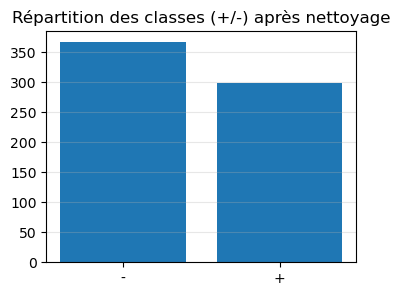

Train : (333, 6) | Test : (333, 6)

Comparaison sur données numériques brutes :

--- CART ---
Confusion matrix:
[[130  53]
 [ 43 107]]
Accuracy: 0.712 | Precision: 0.669 | Recall: 0.713
AUC:      0.712
Final score = (Accuracy + Precision)/2 : 0.690

--- KNN ---
Confusion matrix:
[[128  55]
 [ 64  86]]
Accuracy: 0.643 | Precision: 0.610 | Recall: 0.573
AUC:      0.683
Final score = (Accuracy + Precision)/2 : 0.626

--- MLP ---
Confusion matrix:
[[133  50]
 [ 63  87]]
Accuracy: 0.661 | Precision: 0.635 | Recall: 0.580
AUC:      0.663
Final score = (Accuracy + Precision)/2 : 0.648


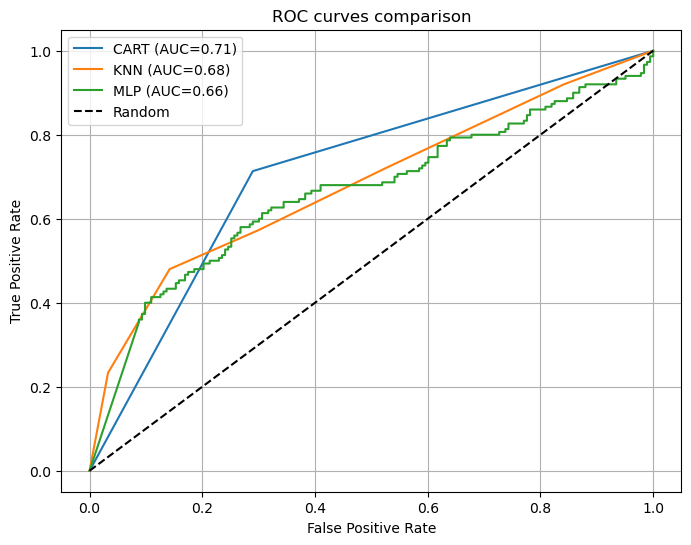


Best model: CART | best score: 0.690

Comparaison après normalisation (StandardScaler) :

--- CART ---
Confusion matrix:
[[130  53]
 [ 42 108]]
Accuracy: 0.715 | Precision: 0.671 | Recall: 0.720
AUC:      0.715
Final score = (Accuracy + Precision)/2 : 0.693

--- KNN ---
Confusion matrix:
[[163  20]
 [ 54  96]]
Accuracy: 0.778 | Precision: 0.828 | Recall: 0.640
AUC:      0.820
Final score = (Accuracy + Precision)/2 : 0.803

--- MLP ---
Confusion matrix:
[[146  37]
 [ 39 111]]
Accuracy: 0.772 | Precision: 0.750 | Recall: 0.740
AUC:      0.827
Final score = (Accuracy + Precision)/2 : 0.761


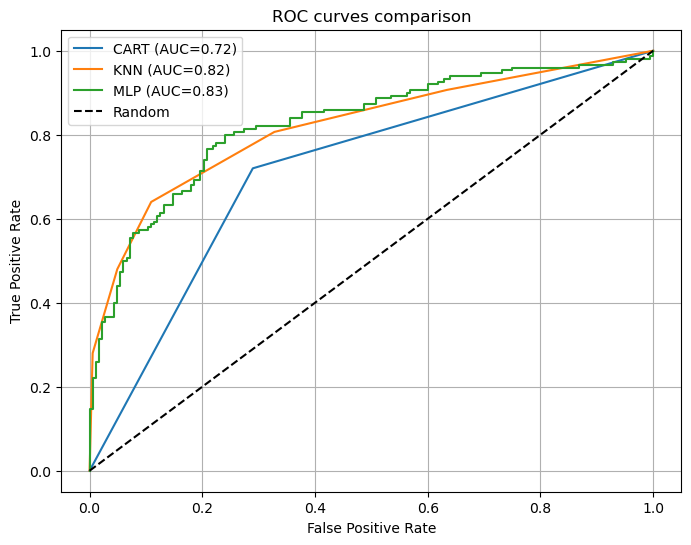


Best model: KNN | best score: 0.803

II.1) Variables numériques (sans valeurs manquantes)
Dataset shape (brut) : (688, 16)
Shape après nettoyage : (666, 6)


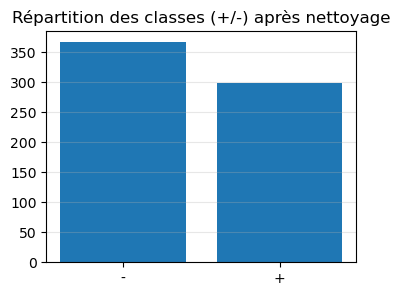

Train : (333, 6) | Test : (333, 6)

Comparaison après normalisation (MinMaxScaler) :

--- CART ---
Confusion matrix:
[[130  53]
 [ 43 107]]
Accuracy: 0.712 | Precision: 0.669 | Recall: 0.713
AUC:      0.712
Final score = (Accuracy + Precision)/2 : 0.690

--- KNN ---
Confusion matrix:
[[150  33]
 [ 56  94]]
Accuracy: 0.733 | Precision: 0.740 | Recall: 0.627
AUC:      0.792
Final score = (Accuracy + Precision)/2 : 0.736

--- MLP ---
Confusion matrix:
[[149  34]
 [ 43 107]]
Accuracy: 0.769 | Precision: 0.759 | Recall: 0.713
AUC:      0.822
Final score = (Accuracy + Precision)/2 : 0.764


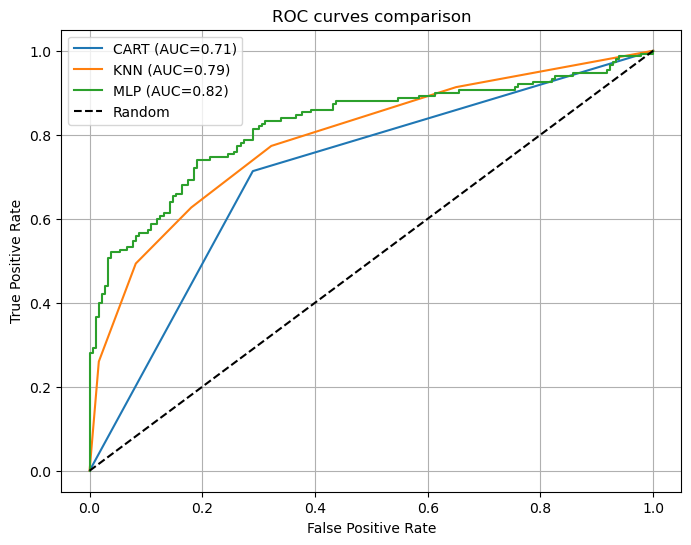


Best model: MLP | best score: 0.764


In [4]:
from utils_part2 import part2_run_numeric_no_missing

# II.1 — Variables numériques uniquement (suppression des lignes avec NaN)
part2_run_numeric_no_missing("credit.data", scaler="standard", show_raw=True)

# Même chose avec MinMaxScaler (on évite de réafficher les résultats "bruts" pour ne pas doubler)
part2_run_numeric_no_missing("credit.data", scaler="minmax", show_raw=False)


<div style="background:#0f172a; color:#e5e7eb; padding:18px 18px; border-radius:14px; border:1px solid #1f2937; line-height:1.55">

  <div style="font-size:22px; font-weight:700; color:#93c5fd; margin-bottom:8px;">
    Analyse — II.1 (variables numériques, sans valeurs manquantes)
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#fbbf24;">Nettoyage + répartition des classes</div>
    <div style="margin-top:6px;">
      On garde uniquement les 6 variables numériques. Les lignes qui contiennent au moins un <code>?</code> sont supprimées :
      on passe de <code>688</code> individus à <code>666</code>. L’histogramme montre un léger déséquilibre, mais rien d’extrême.
    </div>
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#34d399;">Résultats sur données brutes</div>
    <div style="margin-top:6px;">
      Sans normalisation, le meilleur score métier est obtenu par <code>CART</code> (≈ 0.690). 
      C’est cohérent : un arbre de décision est peu sensible aux différences d’échelle entre variables,
      alors que <code>KNN</code> et <code>MLP</code> peuvent être perturbés par des variables “très grandes” par rapport aux autres.
    </div>
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#f472b6;">Effet de la normalisation (StandardScaler)</div>
    <div style="margin-top:6px;">
      Après <code>StandardScaler</code>, on voit une amélioration nette, surtout pour <code>KNN</code> :
      Accuracy ≈ 0.778, AUC ≈ 0.820, score métier ≈ 0.803 (meilleur sur ce test).
      C’est attendu : en centrant/réduisant les variables, les distances deviennent comparables et KNN devient plus pertinent.
    </div>
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#a78bfa;">Test MinMaxScaler</div>
    <div style="margin-top:6px;">
      Avec <code>MinMaxScaler</code>, les performances remontent aussi. Ici, <code>MLP</code> devient le meilleur (score métier ≈ 0.764),
      avec une AUC élevée (≈ 0.822). Sur ce dataset “petit” (666 lignes), le résultat peut varier légèrement selon la normalisation,
      mais l’idée reste la même : KNN/MLP profitent fortement du scaling.
    </div>
  </div>

  <div>
    <div style="font-size:16px; font-weight:700; color:#f87171;">Conclusion (II.1)</div>
    <div style="margin-top:6px;">
      Sur les variables numériques seules, la normalisation est clairement utile. 
      Si on doit retenir un choix simple pour la suite de II.1 : <code>StandardScaler + KNN(k=5)</code> (meilleur score métier ici),
      tout en notant que <code>MinMaxScaler + MLP</code> est aussi une option crédible selon la normalisation choisie.
    </div>
  </div>

</div>


<div style="background:#0f172a; color:#e5e7eb; padding:16px 18px; border-radius:14px; border:1px solid #1f2937; margin-bottom:12px;">
  <div style="font-size:22px; font-weight:700; color:#93c5fd; margin:0;">
    II.2 — Base complète (num + cat) avec données manquantes
  </div>
  <p style="margin:10px 0 0 0; color:#cbd5e1;">
    Objectif : utiliser tout le dataset <code style="color:#e5e7eb;">credit.data</code> (6 variables numériques + 9 catégorielles)
    en traitant les valeurs manquantes par imputation, puis en encodant les variables catégorielles en One-Hot.
  </p>
</div>

<div style="background:#0b1220; padding:14px 18px; border-radius:14px; border:1px solid #1f2937; color:#e5e7eb;">
  <div style="font-size:16px; font-weight:700; color:#fbbf24; margin-top:0;">
    Préparation des données (conforme à l’énoncé)
  </div>
  <ul style="margin:8px 0 14px 18px; color:#d1d5db;">
    <li>Lecture via <code>pandas.read_csv</code> et conversion en <code>numpy</code> via <code>values</code>.</li>
    <li>Séparation <code>X</code> (15 variables) / <code>y</code> (classe <code>+</code> ou <code>-</code>).</li>
    <li>Binarisation de la target : <code>+</code> → 1 et <code>-</code> → 0.</li>
  </ul>

  <div style="font-size:16px; font-weight:700; color:#34d399;">
    Traitement des données manquantes
  </div>
  <ul style="margin:8px 0 14px 18px; color:#d1d5db;">
    <li>Numériques : remplacement <code>?</code> → <code>NaN</code>, conversion <code>float</code>, puis imputation <code>mean</code>.</li>
    <li>Catégorielles : encodage en entiers via <code>np.unique(..., return_inverse=True)</code>, puis imputation <code>most_frequent</code>.</li>
  </ul>

  <div style="font-size:16px; font-weight:700; color:#f472b6;">
    Encodage des catégorielles
  </div>
  <p style="margin:8px 0 14px 0; color:#d1d5db;">
    On applique ensuite un <code>OneHotEncoder</code> sur les 9 variables catégorielles,
    puis on concatène <code>[num_norm]</code> et <code>[cat_onehot]</code> pour obtenir le dataset final.
  </p>

  <div style="font-size:16px; font-weight:700; color:#a78bfa;">
    Évaluation
  </div>
  <p style="margin:8px 0 0 0; color:#d1d5db;">
    Split 50/50 stratifié (<code>random_state=1</code>), puis comparaison de plusieurs modèles
    (CART, KNN, MLP, RandomForest, AdaBoost) avec les mêmes métriques que la partie I :
    matrice de confusion, Accuracy, Précision, Rappel, ROC/AUC.
  </p>
</div>



II.2) Base complète (num + cat) avec imputation + one-hot
Dataset shape (brut) : (688, 16)
Positifs : 305 | Négatifs : 383
Shape num : (688, 6) | Shape cat one-hot : (688, 40)
Shape final : (688, 46)

Comparaison sur base complète préparée :

--- CART ---
Confusion matrix:
[[165  26]
 [ 28 125]]
Accuracy: 0.843 | Precision: 0.828 | Recall: 0.817
AUC:      0.840
Final score = (Accuracy + Precision)/2 : 0.835

--- KNN ---
Confusion matrix:
[[175  16]
 [ 40 113]]
Accuracy: 0.837 | Precision: 0.876 | Recall: 0.739
AUC:      0.887
Final score = (Accuracy + Precision)/2 : 0.857

--- MLP ---
Confusion matrix:
[[163  28]
 [ 31 122]]
Accuracy: 0.828 | Precision: 0.813 | Recall: 0.797
AUC:      0.891
Final score = (Accuracy + Precision)/2 : 0.821

--- RF_200 ---
Confusion matrix:
[[176  15]
 [ 26 127]]
Accuracy: 0.881 | Precision: 0.894 | Recall: 0.830
AUC:      0.920
Final score = (Accuracy + Precision)/2 : 0.888

--- AdaBoost_200 ---
Confusion matrix:
[[172  19]
 [ 32 121]]
Accuracy: 0.852 | 

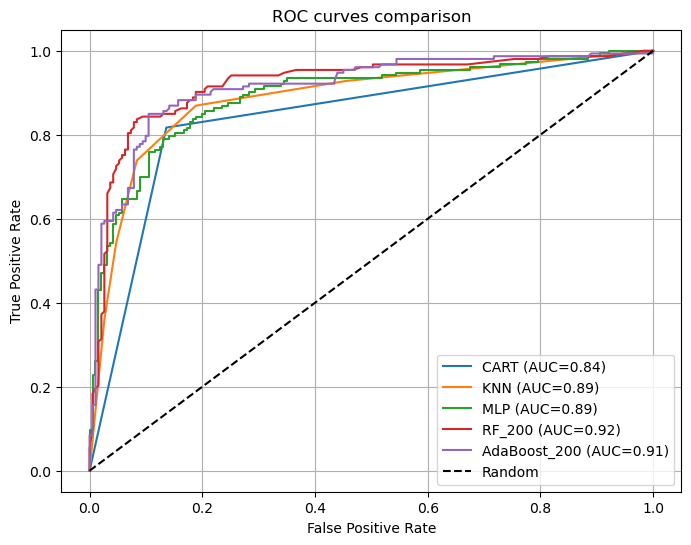


Best model: RF_200 | best score: 0.888

Comparaison sur base complète préparée :

--- CART ---
Confusion matrix:
[[165  26]
 [ 28 125]]
Accuracy: 0.843 | Precision: 0.828 | Recall: 0.817
AUC:      0.840
Final score = (Accuracy + Precision)/2 : 0.835

--- KNN ---
Confusion matrix:
[[167  24]
 [ 32 121]]
Accuracy: 0.837 | Precision: 0.834 | Recall: 0.791
AUC:      0.883
Final score = (Accuracy + Precision)/2 : 0.836

--- MLP ---
Confusion matrix:
[[162  29]
 [ 38 115]]
Accuracy: 0.805 | Precision: 0.799 | Recall: 0.752
AUC:      0.875
Final score = (Accuracy + Precision)/2 : 0.802

--- RF_200 ---
Confusion matrix:
[[176  15]
 [ 26 127]]
Accuracy: 0.881 | Precision: 0.894 | Recall: 0.830
AUC:      0.920
Final score = (Accuracy + Precision)/2 : 0.888

--- AdaBoost_200 ---
Confusion matrix:
[[173  18]
 [ 32 121]]
Accuracy: 0.855 | Precision: 0.871 | Recall: 0.791
AUC:      0.915
Final score = (Accuracy + Precision)/2 : 0.863


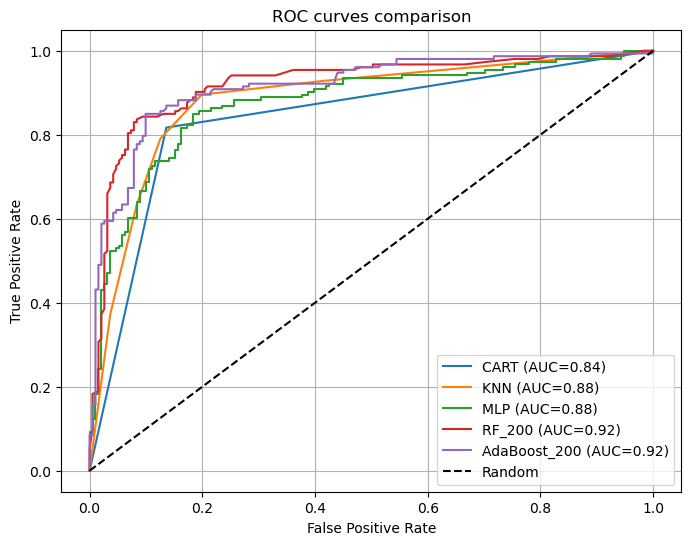


Best model: RF_200 | best score: 0.888


In [5]:
from utils_part2 import part2_run_full_exact_statement

# Test 1 : StandardScaler (affiche toutes les étapes)
part2_run_full_exact_statement("credit.data", use_minmax=False, verbose=True)

# Test 2 : MinMaxScaler (on évite de ré-afficher toutes les étapes)
part2_run_full_exact_statement("credit.data", use_minmax=True, verbose=False)


<div style="background:#0f172a; color:#e5e7eb; padding:18px 18px; border-radius:14px; border:1px solid #1f2937; line-height:1.55">

  <div style="font-size:22px; font-weight:700; color:#93c5fd; margin-bottom:8px;">
    Analyse — II.2 (base complète : numériques + catégorielles, avec manquants)
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#fbbf24;">Prétraitements demandés par l’énoncé</div>
    <div style="margin-top:6px;">
      On utilise les 15 variables : 6 numériques + 9 catégorielles, avec gestion des valeurs manquantes.
      <ul style="margin:8px 0 0 18px;">
        <li>Numériques : remplacement <code>?</code> → <code>NaN</code> puis imputation <code>mean</code>, puis normalisation.</li>
        <li>Catégorielles : encodage entier via <code>np.unique(..., return_inverse=True)</code>, imputation <code>most_frequent</code>, puis <code>OneHotEncoder</code>.</li>
        <li>Construction finale : concaténation <code>[num_normalisées + cat_onehot]</code>.</li>
      </ul>
      Au final on obtient <code>46</code> variables : <code>6</code> numériques + <code>40</code> binaires one-hot.
    </div>
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#34d399;">Résultats</div>
    <div style="margin-top:6px;">
      Sur la base complète préparée, les performances montent nettement par rapport à II.1 (ce qui est logique : on utilise plus d’info).
      Le meilleur modèle est <code>RF_200</code> avec :
      Accuracy ≈ 0.881, Precision ≈ 0.894, Recall ≈ 0.830, AUC ≈ 0.920, score métier ≈ 0.888.
    </div>
  </div>

  <div style="margin-bottom:14px;">
    <div style="font-size:16px; font-weight:700; color:#f472b6;">StandardScaler vs MinMaxScaler</div>
    <div style="margin-top:6px;">
      Les deux normalisations donnent des résultats proches. <code>RF_200</code> reste premier dans les deux cas,
      ce qui est cohérent : une forêt est peu sensible à l’échelle des variables et profite surtout de la richesse
      des variables catégorielles encodées.
    </div>
  </div>

  <div>
    <div style="font-size:16px; font-weight:700; color:#f87171;">Conclusion (II.2)</div>
    <div style="margin-top:6px;">
      La stratégie “imputation + one-hot + concaténation” améliore clairement la qualité de classification.
      Pour la base complète, le choix le plus robuste ici est <code>RandomForest (200 arbres)</code>, avec une AUC élevée (~0.92)
      et le meilleur score métier (~0.888).
    </div>
  </div>

</div>


<div style="background:#0f172a; color:#e5e7eb; padding:14px 16px; border-radius:12px; border:1px solid #1f2937;">
  <h1 style="margin:0; color:#93c5fd;">Conclusion — TP / Projet (Partie I + Partie II)</h1>
  <p style="margin:8px 0 0 0;">
    Objectif global : construire un modèle de scoring, comparer des stratégies de prétraitement,
    sélectionner des variables, valider de manière robuste et proposer une mise en production (pipeline + API).
  </p>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #60a5fa;">
  <h2 style="margin:0; color:#93c5fd;">Partie I — Credit scoring sur <code style="color:#e5e7eb;">credit_scoring.csv</code></h2>
  <ul style="margin:8px 0 0 18px;">
    <li>
      Mise en place d’un protocole reproductible : chargement, analyse rapide des classes, split 50/50 stratifié,
      puis comparaison CART / KNN / MLP avec matrice de confusion, ROC/AUC et score métier.
    </li>
    <li>
      La normalisation (<code style="color:#e5e7eb;">StandardScaler</code>) améliore nettement les modèles sensibles à l’échelle (KNN/MLP),
      et l’ajout de <code style="color:#e5e7eb;">PCA(3)</code> permet d’enrichir l’information (13 → 16 variables).
    </li>
    <li>
      Sélection de variables : importance RandomForest, recherche d’un nombre optimal de variables (<code style="color:#e5e7eb;">best_k = 13</code>),
      et analyse d’explicabilité globale (SHAP).
    </li>
    <li>
      Optimisation des hyperparamètres par <code style="color:#e5e7eb;">GridSearchCV</code> sur le score métier
      <code style="color:#e5e7eb;">(Accuracy + Precision)/2</code>, puis construction d’un pipeline final exporté en
      <code style="color:#e5e7eb;">credit_scoring.pkl</code>.
    </li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #a78bfa;">
  <h2 style="margin:0; color:#c4b5fd;">Validation robuste et production (Q9–Q10)</h2>
  <ul style="margin:8px 0 0 18px;">
    <li>
      Q9 : validation de la mise en production via une API FastAPI — les prédictions et probabilités renvoyées par l’API
      sont identiques au scoring local, ce qui confirme le bon chargement du pickle et le bon ordre des features.
    </li>
    <li>
      Q10 : comparaison robuste par validation croisée 10-fold sur <code style="color:#e5e7eb;">raw</code>/<code style="color:#e5e7eb;">norm</code>/<code style="color:#e5e7eb;">acp</code>
      (prétraitements intégrés dans le pipeline pour éviter toute fuite). Les méthodes d’ensemble dominent,
      et le meilleur modèle en score métier sur <code style="color:#e5e7eb;">acp</code> est XGBoost, exporté en
      <code style="color:#e5e7eb;">credit_scoring_cv.pkl</code>.
    </li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #22c55e;">
  <h2 style="margin:0; color:#86efac;">Partie II — Dataset UCI <code style="color:#e5e7eb;">credit.data</code></h2>
  <ul style="margin:8px 0 0 18px;">
    <li>
      II.1 : travail sur les variables numériques uniquement (6 colonnes) en supprimant les individus incomplets,
      puis comparaison avant/après normalisation (StandardScaler / MinMaxScaler). Les résultats montrent que la normalisation
      change fortement les performances de KNN/MLP, ce qui confirme l’importance du prétraitement.
    </li>
    <li>
      II.2 : utilisation de la base complète (numériques + catégorielles) avec traitement des valeurs manquantes :
      imputation <code style="color:#e5e7eb;">mean</code> (num) / <code style="color:#e5e7eb;">most_frequent</code> (cat),
      encodage One-Hot, puis comparaison de plusieurs modèles. Les modèles d’ensemble (notamment RandomForest) obtiennent
      les meilleurs résultats, confirmant l’intérêt d’exploiter l’ensemble des variables (y compris catégorielles).
    </li>
  </ul>
</div>

<br>

<div style="background:#0b1220; color:#e5e7eb; padding:12px 16px; border-radius:12px; border:1px solid #1f2937; border-left:6px solid #f59e0b;">
  <h2 style="margin:0; color:#fbbf24;">Bilan final</h2>
  <p style="margin:8px 0 0 0;">
    Le projet aboutit à une chaîne complète et reproductible : préparation des données, comparaison de modèles,
    amélioration par prétraitement, sélection de variables, optimisation, validation robuste (CV) et mise en production
    (pipeline sérialisé + API de scoring). Les résultats mettent en évidence deux points majeurs :
    (1) la normalisation est indispensable pour les modèles à distance/optimisation, et (2) les méthodes d’ensemble
    sont les plus performantes et les plus stables sur des données tabulaires de scoring.
  </p>
</div>
